In [71]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [72]:
df = pd.read_csv(r"C:\Users\Pranjal\OneDrive\Desktop\ecomerce.csv")

df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,Risk_Score
0,1,33,5,2,5,2,7,0,2,191.96,1,0.757024
1,1,7,4,4,1,1,11,1,3,172.87,1,0.730017
2,1,31,6,4,1,2,3,1,1,148.40,1,0.822133
3,1,7,5,4,3,1,8,1,3,153.00,1,0.759862
4,1,20,5,2,5,1,7,1,3,186.34,1,0.852308


In [73]:
df.isnull().sum()


Tenure                      0
WarehouseToHome             0
NumberOfDeviceRegistered    0
PreferedOrderCat            0
SatisfactionScore           0
MaritalStatus               0
NumberOfAddress             0
Complain                    0
DaySinceLastOrder           0
CashbackAmount              0
Churn                       0
Risk_Score                  0
dtype: int64

In [74]:
df.dropna(inplace=True)

In [75]:
df.fillna(df.median(numeric_only=True), inplace=True)

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,Risk_Score
0,1,33,5,2,5,2,7,0,2,191.96,1,0.757024
1,1,7,4,4,1,1,11,1,3,172.87,1,0.730017
2,1,31,6,4,1,2,3,1,1,148.40,1,0.822133
3,1,7,5,4,3,1,8,1,3,153.00,1,0.759862
4,1,20,5,2,5,1,7,1,3,186.34,1,0.852308
...,...,...,...,...,...,...,...,...,...,...,...,...
75,1,26,5,4,4,1,3,1,1,149.13,1,0.763872
76,0,8,4,2,4,2,8,1,2,199.07,1,0.866192
77,1,13,4,4,5,1,6,1,3,145.73,1,0.739708
78,1,31,6,4,1,2,3,1,1,136.18,1,0.815668


In [76]:
df.drop_duplicates(inplace=True)

print(df.shape)



(80, 12)


In [77]:
print("Total Customers:", len(df))

Total Customers: 80


In [78]:
print("Churned Customers:", df["Churn"].sum())

Churned Customers: 73


In [79]:
churn_rate = (df["Churn"].sum()/len(df))*100

print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 91.25%


In [80]:
category_churn = (
    df.groupby("PreferedOrderCat")["Churn"]
    .mean()
    * 100
)

print(category_churn)

PreferedOrderCat
0    100.000000
2     92.307692
3    100.000000
4     89.361702
Name: Churn, dtype: float64


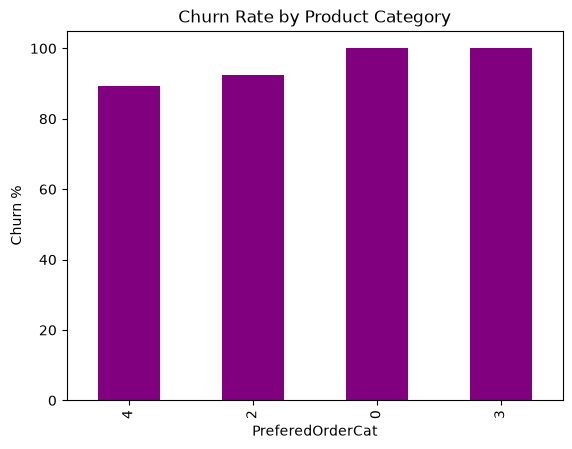

In [81]:
import matplotlib.pyplot as plt

category_churn.sort_values().plot(
    kind="bar",
    color="purple"
)

plt.title("Churn Rate by Product Category")
plt.ylabel("Churn %")
plt.show()

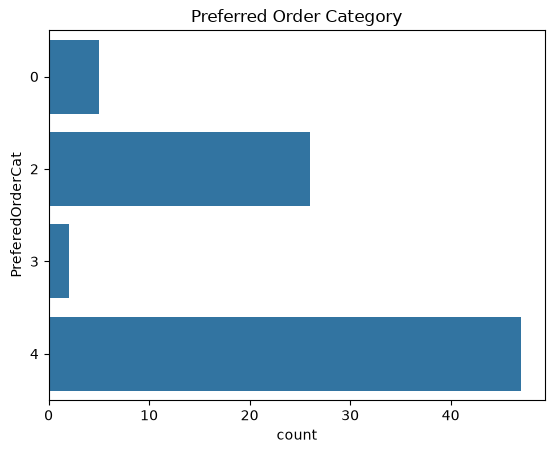

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(
    y="PreferedOrderCat",
    data=df
)

plt.title("Preferred Order Category")
plt.show()



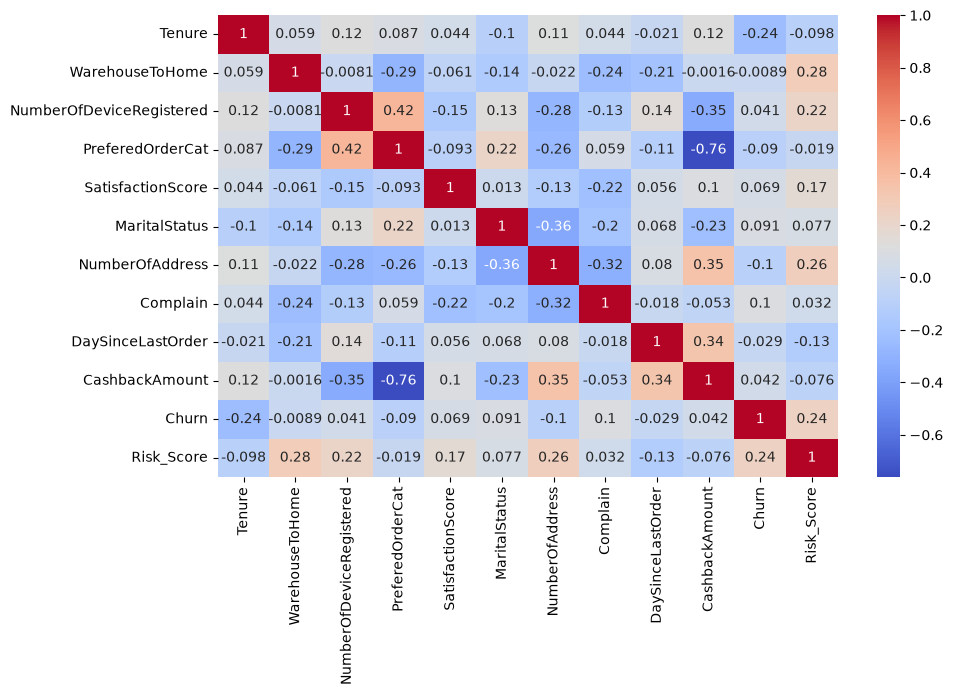

In [83]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.show()

In [84]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["PreferedOrderCat"] = le.fit_transform(
    df["PreferedOrderCat"]
)

df["MaritalStatus"] = le.fit_transform(
    df["MaritalStatus"]
)

In [85]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

In [86]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [87]:
from sklearn.metrics import accuracy_score

pred = model.predict(X_test)

print(
    accuracy_score(y_test,pred)
)

0.8125


In [88]:
df["Risk_Score"] = model.predict_proba(X)[:,1]

high_risk = df[df["Risk_Score"] > 0.7]

high_risk.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,Risk_Score
0,1,33,5,1,5,2,7,0,2,191.96,1,0.990416
1,1,7,4,3,1,1,11,1,3,172.87,1,0.858736
2,1,31,6,3,1,2,3,1,1,148.40,1,0.910960
3,1,7,5,3,3,1,8,1,3,153.00,1,0.951325
4,1,20,5,1,5,1,7,1,3,186.34,1,0.986477


In [89]:
high_risk.to_csv(
    "high_risk_customers.csv",
    index=False
)